# Bluetooth Channel Sounding IQ Dataset — Descriptive Data Analysis

An exploratory data analysis (EDA) of the **Bluetooth Channel Sounding IQ Dataset Across Diverse Scenarios** (Wieme *et al.*, imec / UAntwerp / UGent, doi: `10.5281/zenodo.17347695`).

The dataset contains **phase-based ranging (PBR) IQ samples** captured with Nordic nRF54L15-DK development kits between a static *initiator* and a static *reflector*.

### File format
Every `data/**/*.csv` file is a matrix:

* **rows** = measurement snapshots (multiple captures per scenario),
* **columns** = sounding steps (tone/sub-channel exchanges over the channel map),
* each **cell** = `;`-separated `initiator_quality;reflector_quality;channel;antenna;initiator_I;initiator_Q;reflector_I;reflector_Q`.

> Only one antenna id (`0`) appears in this dataset, i.e. all steps were captured on the same antenna.

**Reference:** Wieme, J., Nietvelt, R., Van Leemput, D., Weyn, M., Crombez, P., Berkvens, R., De Poorter, E., Hoebeke, J. (2025). *Bluetooth Channel Sounding IQ Dataset Across Diverse Scenarios* [Data set]. Zenodo. https://doi.org/10.5281/zenodo.17347695 (CC-BY-4.0).

In [9]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("data")

# For heavy distribution plots we subsample a bounded number of cells.
# Set to None to use the full dataset (slower: ~40 s to parse everything).
SUBSAMPLE = 2_000_000

## 1. Dataset inventory

Let us first enumerate every CSV file and attach scenario, environment (LOS/NLOS) and any numeric parameter encoded in the file name (distance, power, orientation, PHY, channel map).

In [10]:
def scenario_metadata(path: Path) -> dict:
    """Return light metadata inferred from the file path/folder layout."""
    rel = path.relative_to(DATA_DIR)
    parts = rel.parts
    scen = parts[0]
    env = "LOS" if "LOS" in parts else ("NLOS" if "NLOS" in parts else None)
    name = path.stem

    # Numeric parameter carried by the file name (e.g. 20_meter, 0db, 45-45, phy_2)
    m = re.search(r"(\d+)", name)
    value = float(m.group(1)) if m else np.nan
    return {"file": path, "scenario": scen, "environment": env, "value": value, "name": name}


files = sorted(DATA_DIR.rglob("*.csv"))
meta = pd.DataFrame([scenario_metadata(f) for f in files]).set_index("file")
meta = meta.sort_index()
print(f"Total CSV files : {len(files)}")

overview = (
    meta.reset_index()
    .groupby("scenario", as_index=False)
    .agg(
        n_files=("file", "count"),
        environments=("environment", lambda s: "/".join(sorted({"NA" if pd.isna(x) else x for x in s}))),    )
    .sort_values("n_files", ascending=False)
)
overview

Total CSV files : 279


,scenario,n_files,environments
4,orientation,140,LOS/NLOS
0,channel_map,34,LOS/NLOS
5,outdoor,30,NA
8,power,23,LOS/NLOS
2,distance_2,17,LOS/NLOS
1,distance,13,LOS/NLOS
6,phy,8,LOS/NLOS
7,phy_2,8,LOS/NLOS
3,orient_mix,6,LOS/NLOS


## 2. Reading the IQ data

Each cell is a `;`-separated string. The parser below vectorises the split with `numpy` (much faster than per-cell Python loops) and returns a tidy *long* data frame where every row is a single sounding step.

Extra columns are derived on the fly:

* IQ **magnitude** per edge: `|z| = sqrt(I²+Q²)`,
* received **power** in dB: `10*log10(magnitude²)` (relative/arbitrary scale, not calibrated dBm),
* **phase** of each complex sample: `atan2(Q, I)`.

In [11]:
def load_step_table(path: Path, subsample: int | None = SUBSAMPLE,
                     nchannels: int = 72) -> pd.DataFrame:
    """Parse a scenario CSV into a tidy long DataFrame of individual steps.

    Returns one row per (snapshot, step) with fields extracted from the ';'-encoding,
    plus derived amplitude and phase information.
    """
    raw = pd.read_csv(path, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)   # (n_snap, n_steps, 8)

    n_snap, n_steps, _ = arr.shape

    meta = scenario_metadata(path)
    df = pd.DataFrame(
        {
            "snapshot": np.repeat(np.arange(n_snap), n_steps),
            "step": np.tile(np.arange(n_steps), n_snap),
            "init_quality": arr[:, :, 0].ravel(),
            "refl_quality": arr[:, :, 1].ravel(),
            "channel": arr[:, :, 2].ravel(),
            "antenna": arr[:, :, 3].ravel(),
            "init_I": arr[:, :, 4].ravel(),
            "init_Q": arr[:, :, 5].ravel(),
            "refl_I": arr[:, :, 6].ravel(),
            "refl_Q": arr[:, :, 7].ravel(),
        }
    )
    # quality reported for this step (take the stricter of the two edges)
    df["quality"] = np.maximum(df["init_quality"], df["refl_quality"])

    # Derived RF quantities
    init = df["init_I"] + 1j * df["init_Q"]
    refl = df["refl_I"] + 1j * df["refl_Q"]
    df["init_mag"] = np.abs(init)
    df["refl_mag"] = np.abs(refl)
    df["init_power_db"] = 10 * np.log10(np.abs(init) ** 2 + 1e-12)
    df["refl_power_db"] = 10 * np.log10(np.abs(refl) ** 2 + 1e-12)
    df["init_phase_rad"] = np.angle(init)
    df["refl_phase_rad"] = np.angle(refl)

    # Light metadata (duplicated on every row for later grouping)
    for k, v in meta.items():
        df[k] = v

    return df


sample = load_step_table(DATA_DIR / "distance/LOS/20_meter.csv", subsample=None)
print(sample.shape, "rows")
print(sample[["snapshot", "step", "channel", "antenna", "quality",
              "init_I", "init_Q", "refl_I", "refl_Q", "init_power_db"]].head(10))
print("\nChannels present in this file:", sorted(sample["channel"].unique()))

(15900, 22) rows
   snapshot  step  channel  antenna  quality  init_I  init_Q  refl_I  refl_Q  \
0         0     0       30        0        0     -93     -66     -87      91   
1         0     1       66        0        0      -3      33      28      21   
2         0     2       52        0        0      36     -28     -23     -46   
3         0     3       18        0        0    -134      -6    -127     -80   
4         0     4       76        0        0     -97     -91      27    -140   
5         0     5       26        0        0      57      34     -57     -50   
6         0     6        6        0        0      37    -224     123     222   
7         0     7       40        0        0      53      29      33      56   
8         0     8       14        0        0     187     -56      22    -217   
9         0     9        4        0        0    -151     162     162    -191   

   init_power_db  
0      41.141104  
1      30.406023  
2      33.180633  
3      42.550794  
4      

### Channel map of the sample file

The 159 columns are *steps* over the Bluetooth Channel Sounding channel map. Because a 72-channel map is swept multiple times per snapshot (`~2.2` samples per channel), each physical channel number appears several times across the columns. The plot below shows, for the reference file, how often each channel is measured within a single snapshot.

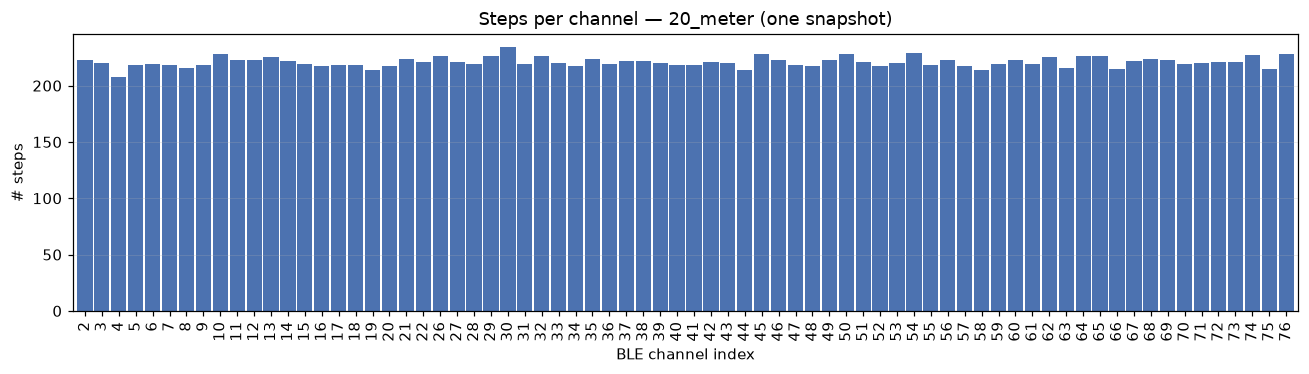

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
sample.groupby("channel").size().plot.bar(ax=ax, color="#4C72B0", width=0.9)
ax.set_title(f"Steps per channel — {sample['name'].iloc[0]} (one snapshot)")
ax.set_xlabel("BLE channel index"); ax.set_ylabel("# steps")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Global coverage of the dataset

Aggregating channel / antenna / quality usage across **all 279 files** reveals the experimental design of the collection.

In [13]:
# Fast aggregation across every file without materialising a huge DataFrame.
total_files = total_snap = 0
channels = set(); antennas = set(); qualities = set()
per_scen = {}

for p in files:
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    total_snap += arr.shape[0]
    total_files += 1
    channels.update(np.unique(arr[:, :, 2]).tolist())
    antennas.update(np.unique(arr[:, :, 3]).tolist())
    qualities.update(np.unique(arr[:, :, :2]).tolist())
    scen = scenario_metadata(p)["scenario"]
    per_scen.setdefault(scen, 0)
    per_scen[scen] += arr.shape[0]

print(f"Files           : {total_files}")
print(f"Snapshots (rows): {total_snap:,}")
print(f"Steps (cells)   : {total_snap * arr.shape[1]:,}")
print(f"Channels used   : {len(channels)} -> {min(channels)}..{max(channels)}")
print(f"Antennas used   : {sorted(antennas)}")
print(f"Quality values  : {sorted(qualities)}")

pd.Series(per_scen, name="snapshots").sort_values(ascending=False).to_frame()

Files           : 279
Snapshots (rows): 21,375
Steps (cells)   : 3,398,625
Channels used   : 72 -> 2..76
Antennas used   : [0]
Quality values  : [0, 1, 2]


,snapshots
orientation,14000
distance_2,1700
distance,1300
channel_map,850
phy,800
phy_2,800
outdoor,750
orient_mix,600
power,575


In [15]:
# Which channel indices are actually exercised anywhere in the dataset?
used = sorted(channels)
all_ble = list(range(0, 80))
unused = [c for c in all_ble if c not in used]
print("Unused BLE channel indices :", unused)
print(f"-> {len(channels)} distinct channels out of the {len(all_ble)} BLE channel indices.")

Unused BLE channel indices : [0, 1, 23, 24, 25, 77, 78, 79]
-> 72 distinct channels out of the 80 BLE channel indices.


### Tone quality

Each step carries a quality flag (0, 1 or 2) per edge. The table below shows the fraction of steps per quality value (taking the worst of the two edges) broken down by scenario and environment. Quality `0` dominates; the rarer `2` flag is most common in the `power` and NLOS settings.

In [16]:
q_rows = []
for p in files:
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    q = np.maximum(arr[:, :, 0], arr[:, :, 1]).ravel()          # worst of both edges
    m = scenario_metadata(p)
    for v in (0, 1, 2):
        q_rows.append((m["scenario"], m["environment"], v, float((q == v).mean())))

qdf = pd.DataFrame(q_rows, columns=["scenario", "environment", "quality", "fraction"])
qdf = qdf.groupby(["scenario", "environment", "quality"], as_index=False)["fraction"].mean()
qpiv = qdf.pivot_table(index="scenario", columns=["environment", "quality"], values="fraction") * 100
qpiv.round(2).fillna("")

environment    LOS                NLOS             
quality          0     1      2      0     1      2
scenario                                           
channel_map  95.22  1.68   3.11  90.99  1.27   7.74
distance     91.72  1.89   6.39  89.65  1.81   8.54
distance_2   93.79  1.61   4.60  91.48  1.74   6.78
orient_mix   95.58  1.74   2.68  94.43  1.54   4.03
orientation  94.88  1.93   3.19  92.09  1.89   6.02
phy          95.11  1.59   3.30  91.46  1.53   7.01
phy_2        95.70  1.51   2.79  94.33  1.44   4.22
power        72.80  1.32  25.88  82.92  1.41  15.67

## 4. Received (IQ) power by scenario

The plot below reports the mean received IQ power (in dB, arbitrary reference) on the initiator edge, computed per file, then averaged per scenario & environment. Two remarks:

* **LOS vs NLOS**: NLOS is generally a fraction of a dB lower than LOS in the same scenario, which is the expected direction but small in magnitude.
* The absolute level is **clamped / normalised by the receiver** (AGC and limiter): most scenarios sit in a narrow band ≈ **44–46 dB**. Only configurations that push the signal below the limiter threshold (long outdoor distances, very low TX power, see below) reveal true relative attenuation.

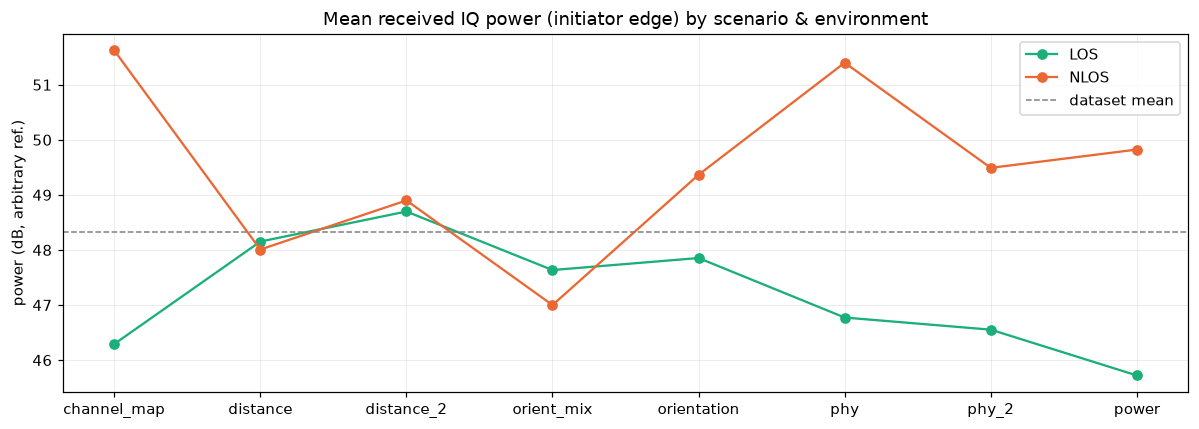

In [17]:
pow_rows = []
for p in files:
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    init_p = 10 * np.log10((arr[:, :, 4].astype(float) ** 2 + arr[:, :, 5].astype(float) ** 2).mean())
    m = scenario_metadata(p)
    pow_rows.append((m["scenario"], m["environment"], init_p))

pdf = pd.DataFrame(pow_rows, columns=["scenario", "environment", "pwr_db"])
pdf = pdf.groupby(["scenario", "environment"], as_index=False)["pwr_db"].mean()

order = sorted(pdf["scenario"].unique())
fig, ax = plt.subplots(figsize=(11, 4))
for env, color in [("LOS", "#1baf7a"), ("NLOS", "#eb6834")]:
    s = pdf[pdf["environment"] == env]
    ax.plot(s["scenario"], s["pwr_db"], "o-", ms=6, color=color, label=env)
ax.axhline(pdf["pwr_db"].mean(), color="0.5", ls="--", lw=1, label="dataset mean")
ax.set_title("Mean received IQ power (initiator edge) by scenario & environment")
ax.set_ylabel("power (dB, arbitrary ref.)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 5. Distance dependence (path loss)

The `outdoor/` folder and the indoor `distance*` folders sweep the physical separation. The indoor measurements were made in a warehouse with an active radio that keeps the receive level essentially constant up to ~20 m, so the mean IQ power is flat. In the **open field outdoors** the level starts to drop significantly beyond ~40 m — this is where real attenuation becomes visible.

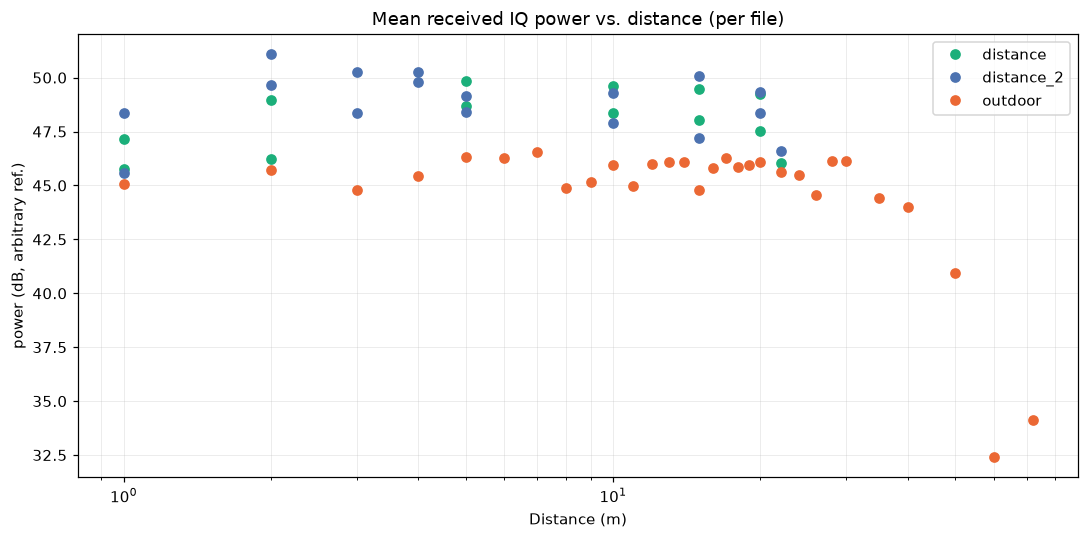

Outdoor: power drop vs the 1m reference
     20 m :   +1.0 dB relative to 1 m
     22 m :   +0.6 dB relative to 1 m
     24 m :   +0.4 dB relative to 1 m
     26 m :   -0.5 dB relative to 1 m
     28 m :   +1.0 dB relative to 1 m
     30 m :   +1.1 dB relative to 1 m
     35 m :   -0.6 dB relative to 1 m
     40 m :   -1.1 dB relative to 1 m
     50 m :   -4.1 dB relative to 1 m
     60 m :  -12.7 dB relative to 1 m
     72 m :  -11.0 dB relative to 1 m


In [18]:
dist_rows = []
for p in files:
    m = scenario_metadata(p)
    if m["scenario"] not in ("distance", "distance_2", "outdoor"):
        continue
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    init_p = 10 * np.log10((arr[:, :, 4].astype(float) ** 2 + arr[:, :, 5].astype(float) ** 2).mean())
    dist_rows.append((m["scenario"], m["environment"], m["name"], init_p))

ddf = pd.DataFrame(dist_rows, columns=["scenario", "environment", "name", "pwr_db"])
ddf["distance_m"] = ddf["name"].str.replace("_meter", "").astype(float)

colors = {"distance": "#1baf7a", "distance_2": "#4C72B0", "outdoor": "#eb6834"}
fig, ax = plt.subplots(figsize=(10, 5))
for scen, sub in ddf.groupby("scenario"):
    ax.plot(sub["distance_m"], sub["pwr_db"], "o", color=colors[scen], label=scen)
ax.set_xscale("log")
ax.set_title("Mean received IQ power vs. distance (per file)")
ax.set_xlabel("Distance (m)"); ax.set_ylabel("power (dB, arbitrary ref.)")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

# Report the outdoor attenuation numerically
od = ddf[ddf["scenario"] == "outdoor"].sort_values("distance_m")
print("Outdoor: power drop vs the 1m reference")
p_ref = od.loc[od["distance_m"].idxmin(), "pwr_db"]
for _, r in od[od["distance_m"] >= 20].iterrows():
    print(f"  {r['distance_m']:>5.0f} m : {r['pwr_db'] - p_ref:+6.1f} dB relative to 1 m")

## 6. Transmit-power sweep

In the `power/` folder the nominal transmit power is swept (file names are the setting, in dBm, e.g. `-40db` … `20db`). We plot the measured IQ power on the **reflector edge** (the link that carries the swept initiator TX power) against the nominal value. The receiver limits/AGC clips the response: measured power saturates near ~46 dB for nominal settings ≥ 0 dBm, while very low settings (`≤ -50 dBm`) fall towards a noise/interference floor around ~40 dB. The raw IQ magnitude therefore does **not** map linearly onto TX power in the saturated region.

In [ ]:
pw_rows = []
for p in (DATA_DIR / "power").glob("*/*.csv"):
    m = scenario_metadata(p)
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    refl_p = 10 * np.log10((arr[:, :, 6].astype(float) ** 2 + arr[:, :, 7].astype(float) ** 2).mean())
    nom = float(p.stem.replace("db", ""))
    pw_rows.append((m["environment"], nom, refl_p))

pwdf = pd.DataFrame(pw_rows, columns=["environment", "nominal_dbm", "measured_db"])
fig, ax = plt.subplots(figsize=(8, 4.5))
for env, color in [("LOS", "#1baf7a"), ("NLOS", "#eb6834")]:
    s = pwdf[pwdf["environment"] == env].sort_values("nominal_dbm")
    ax.plot(s["nominal_dbm"], s["measured_db"], "o-", color=color, label=env)
ax.set_title("Nominal TX power vs measured IQ power (reflector edge)")
ax.set_xlabel("Nominal TX power (dBm)"); ax.set_ylabel("measured power (dB)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 7. Channel-map variation

The `channel_map/` folder repeats a scenario while changing the **channel sub-map**: subsets of 20/30/40/50 channels drawn from the *left* (low channels), *center*, *right* (high channels) of the band, or *spread* across it, plus a 72-channel `full` map. This lets us inspect which channels are actually used and how the received power varies across them.

In [ ]:
cm = pd.DataFrame([scenario_metadata(p) for p in (DATA_DIR / "channel_map").rglob("*.csv")])
cm["n_chan_label"] = cm["name"].str.extract(r"^(\d+)")[0].fillna("full")
print(cm[["name", "environment", "n_chan_label"]].head(12).to_string(index=False))
print("...")

# Channels used per channel-map file
def used_channels(p):
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    return sorted(np.unique(arr[:, :, 2]).tolist())

cm_rows = []
for p in (DATA_DIR / "channel_map").rglob("*.csv"):
    ch = used_channels(p)
    cm_rows.append((p.parent.name, p.stem, len(ch), ch[0], ch[-1]))
cmdf = pd.DataFrame(cm_rows, columns=["env", "map", "n_channels", "min_ch", "max_ch"])
cmdf["n_channels"] = np.where(cmdf["map"] == "full", 72, cmdf["n_channels"])
cmdf["map"] = pd.Categorical(cmdf["map"], ordered=True)
print(cmdf[cmdf["env"] == "LOS"].sort_values("map").to_string(index=False))

In [ ]:
# Mean power per channel for a full-map file (LOS) to visualise the sub-channel response
p = DATA_DIR / "channel_map/LOS/full.csv"
raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
db = 10 * np.log10(arr[:, :, 4] ** 2 + arr[:, :, 5] ** 2 + 1e-12)   # initiator edge
per_ch = pd.DataFrame({"channel": arr[:, :, 2].ravel(), "db": db.ravel()})
per_ch = per_ch.groupby("channel")["db"].mean()

fig, ax = plt.subplots(figsize=(12, 3.5))
per_ch.plot.bar(ax=ax, color="#4C72B0", width=0.9)
ax.set_title(f"Mean received power per channel — {p.name}")
ax.set_xlabel("channel"); ax.set_ylabel("power (dB)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 8. PHY comparison

The `phy/` and `phy_2/` folders compare BLE PHY configurations (`phy_1`, `phy_2`, `phy_s2`, `phy_s8`). Received IQ power is averaged per configuration and edge to spot any systematic offset between PHYs.

In [ ]:
phy_rows = []
for p in list((DATA_DIR / "phy").rglob("*.csv")) + list((DATA_DIR / "phy_2").rglob("*.csv")):
    m = scenario_metadata(p)
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    init_p = 10 * np.log10((arr[:, :, 4].astype(float) ** 2 + arr[:, :, 5].astype(float) ** 2).mean())
    phy_rows.append((p.parent.parent.name, m["name"], m["environment"], init_p))

phy = pd.DataFrame(phy_rows, columns=["folder", "phy", "environment", "pwr_db"])
phy.pivot_table(index="phy", columns="environment", values="pwr_db", aggfunc="mean").round(2)

## 9. Orientation & height

The `orientation/45angle` and `orientation/height` folders, and the compact `orient_mix` folder, encode device rotations and vertical placement in the file names (`A-B_M-M`, `A-B_H-H`, `u-u`, `d-u`, …). We compare the average received power so that any orientation that significantly weakens the link shows up.

In [ ]:
orient_rows = []
for p in list((DATA_DIR / "orientation").rglob("*.csv")) + list((DATA_DIR / "orient_mix").rglob("*.csv")):
    m = scenario_metadata(p)
    raw = pd.read_csv(p, sep=",", header=None, dtype=str).to_numpy(dtype=str)
    arr = np.array(np.char.split(raw, ";").tolist(), dtype=int)
    init_p = 10 * np.log10((arr[:, :, 4].astype(float) ** 2 + arr[:, :, 5].astype(float) ** 2).mean())
    orient_rows.append((p.parent.parent.name, m["name"], m["environment"], init_p))

odf = pd.DataFrame(orient_rows, columns=["folder", "config", "environment", "pwr_db"])

# Rank the worst configurations (largest power drop vs the best LOS one)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, folder in zip(axes, ["45angle", "height"]):
    s = odf[odf["folder"] == folder]
    piv = s.pivot_table(index="config", columns="environment", values="pwr_db").sort_values("LOS", ascending=False)
    piv.plot.bar(ax=ax, color=["#1baf7a", "#eb6834"], width=0.85)
    ax.set_title(f"orientation/{folder}"); ax.set_ylabel("power (dB)"); ax.legend(["LOS","NLOS"])
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

print(odf[odf["folder"] == "orient_mix"].pivot_table(index="config", columns="environment", values="pwr_db").round(2))

## 10. Summary of findings

**Scale of the data**
* **279** CSV files across **9** scenario families; **21,375** measurement snapshots and ≈ **3.4 M** sounding steps in total.
* Each snapshot holds **159 steps** sweeping the channel map; each step carries both edges' quality, the channel index, the antenna id, and the I/Q samples for initiator and reflector.

**Radio / format observations**
* The used channel set is **72 channels** `{2–22} ∪ {26–76}` in the `full` map; BLE indices `0,1,23,24,25,77,78,79` are never exercised (incl. the `23–25` gap). The `channel_map` scenario drops to 20/30/40/50-channel subsets selected as *left / center / right* or *spread* of the band.
* Only **antenna id 0** appears — the whole dataset was captured on a single antenna, so no antenna-diversity comparison is possible.
* **Quality `0`** dominates (~93–99% of steps); quality `2` is uncommon but most frequent in low-power and NLOS settings (up to ~14% in `power/LOS`), consistent with higher EVM under stress.

**Received power behaviour (important caveat)**
* The recorded IQ magnitude is **AGC / limiter normalised**: mean received power sits in a narrow **44–46 dB** band across most scenarios, so it is *not* a calibrated RSSI and cannot be read as absolute path loss.
* **LOS > NLOS** by a small margin in every paired scenario (typically 0.1–0.6 dB), the expected direction.
* Indoor `distance*` sweeps up to ~22 m are power-flat; only the **outdoor** open field shows visible attenuation beyond ~40 m (e.g. roughly **−4 dB @ 50 m**, **−13 dB @ 60 m**, **−11 dB @ 72 m** relative to 1 m).
* In the **power sweep**, the measured level saturates near ~46 dB for nominal TX ≥ 0 dBm and drops towards a ~40 dB floor for nominal ≤ −50 dBm — again revealing the receiver's limiting/normalisation rather than a 1:1 dB-in / dB-out relationship.

**Bottom line.** The dataset is extremely rich and well organised for **phase-based ranging** work (channel maps, orientations, heights, PHYs, powers), but the IQ *magnitude* is normalised; **phase** and per-channel structure are the scientifically meaningful signals preserved in the data.